# Measuring the risk of a self-financing hedge

This native Julia companion retains the public observations, original Float64 design, path seeds, initial policy weights, training budgets, cost accounting and risk preference. Shared primitive normal draws and unfitted parameters preserve the original numerical inputs; Julia computes all generated prices, fitted policies, gradients, cash flows and risk summaries. Timings measure the current native run. Displayed date indices retain the original zero-based convention. Figures use the requested dark theme and native outputs are saved under `outputs/julia`.

## Simulating paths at a public market scale

The generated price process is

$$
S_{k+1}=S_k\exp\!\left[\left(\mu-\frac{\sigma^2}{2}\right)\Delta t+\sigma\sqrt{\Delta t}\,Z_{k+1}\right],
\qquad Z_{k+1}\sim N(0,1).
$$

Here, $S_k$ is the price at date $k$, $\mu$ is the declared drift, $\sigma$ is the annual volatility, and $\Delta t=T/N$ is the time between trades. The variables $Z_{k+1}$ are independent standard normal draws. The volatility scale comes from fixed public NASDAQ Composite observations, while the option paths are generated teaching data.

### Checking moments under a fixed design

Row,Symbol,Description,Unit
,String,String,String
1,S_k,Underlying price at date k,Normalized price
2,K,Call strike,Normalized price
3,T,Time to maturity,Years
4,N,Number of trading steps,Count
5,phi_k,Shares held during interval k,Shares
6,c,Proportional trading cost rate,Fraction of traded value
7,lambda,Entropic risk aversion,Inverse cash flow unit
8,P,Terminal hedge cash flow,Cash flow unit


Row,Feature,Choice
,String,String
1,Underlying assets,One
2,Liability,Short European call
3,Path law,Generated geometric Brownian motion
4,Interest and dividend rates,Zero
5,Trading cost,Proportional to traded value
6,Final position,Fully liquidated
7,Risk measure,Entropic risk
8,Final evaluation,Independent generated paths


Row,Check,Value,Pass
,String,Int64,String
1,Rows in fixed file,8348,Pass
2,Rows in design dates,5477,Pass
3,Observed index levels,5287,Pass
4,Observed log returns,5286,Pass
5,Duplicate dates,0,Pass
6,Nonpositive observed levels,0,Pass


7,Download during execution,None


Row,Statistic,Value
,String,Float64
1,Observations,5286.0
2,Mean daily log return,0.000342608
3,Daily standard deviation,0.0159977
4,Annualized standard deviation,0.253956
5,Minimum,-0.101684
6,First percentile,-0.0443805
7,Median,0.0011913
8,Ninety-ninth percentile,0.0435889
9,Maximum,0.132546


Row,Parameter,Value
,String,Real
1,Spot,1.0
2,Strike,1.0
3,Maturity Days,30
4,Maturity,0.0821918
5,Volatility,0.253956
6,Drift,0.0
7,Steps,20
8,Cost Rate,0.002
9,Risk Aversion,3.0


Row,Item,Value
,String,Any
1,Generated object,Option price paths and hedge cash flows
2,Why generation is necessary,No approved public option panel contains the required synchronized paths and cost rule
3,Public input,Annualized volatility scale only
4,Generated market claim,None
5,Primary path seed,33001
6,Download during execution,None


Row,Quantity,Observed,Target,Tolerance,Pass
,String,Float64,Float64,Float64,String
1,Terminal log-return mean,-0.00284232,-0.00265043,0.00321765,Pass
2,Terminal log-return standard deviation,0.0728592,0.072807,0.00227536,Pass
3,Smallest generated price,0.762214,0.0,0.0,Pass


Row,Check,Value,Pass
,String,Any,String
1,Repeated seed gives identical paths,true,Pass
2,Path array rows,8192,Pass
3,Path array columns,21,Pass
4,All prices finite,true,Pass


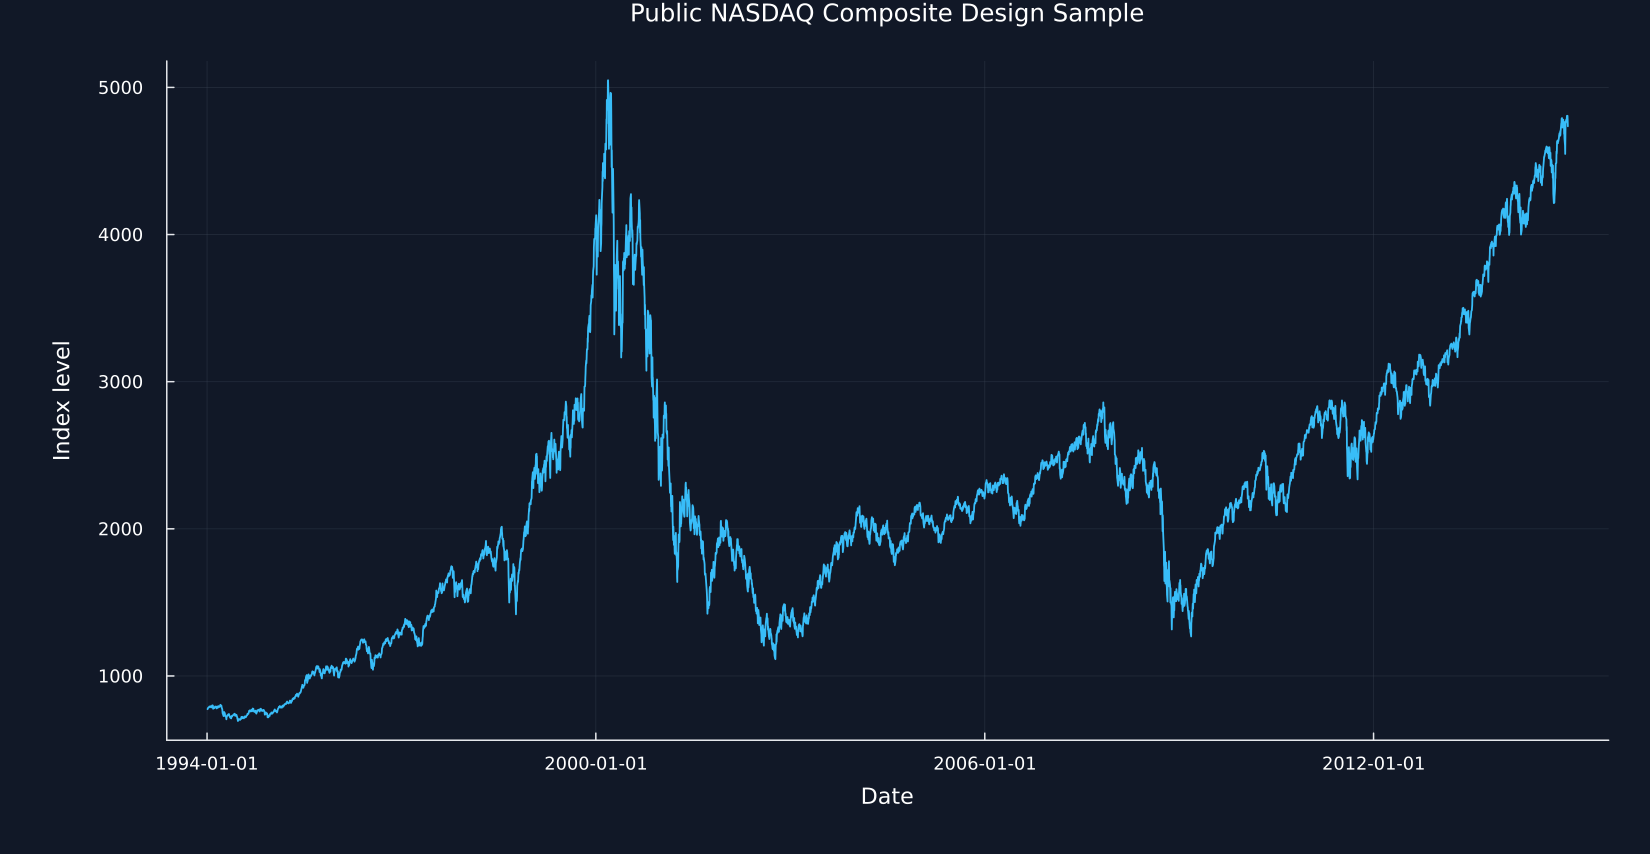

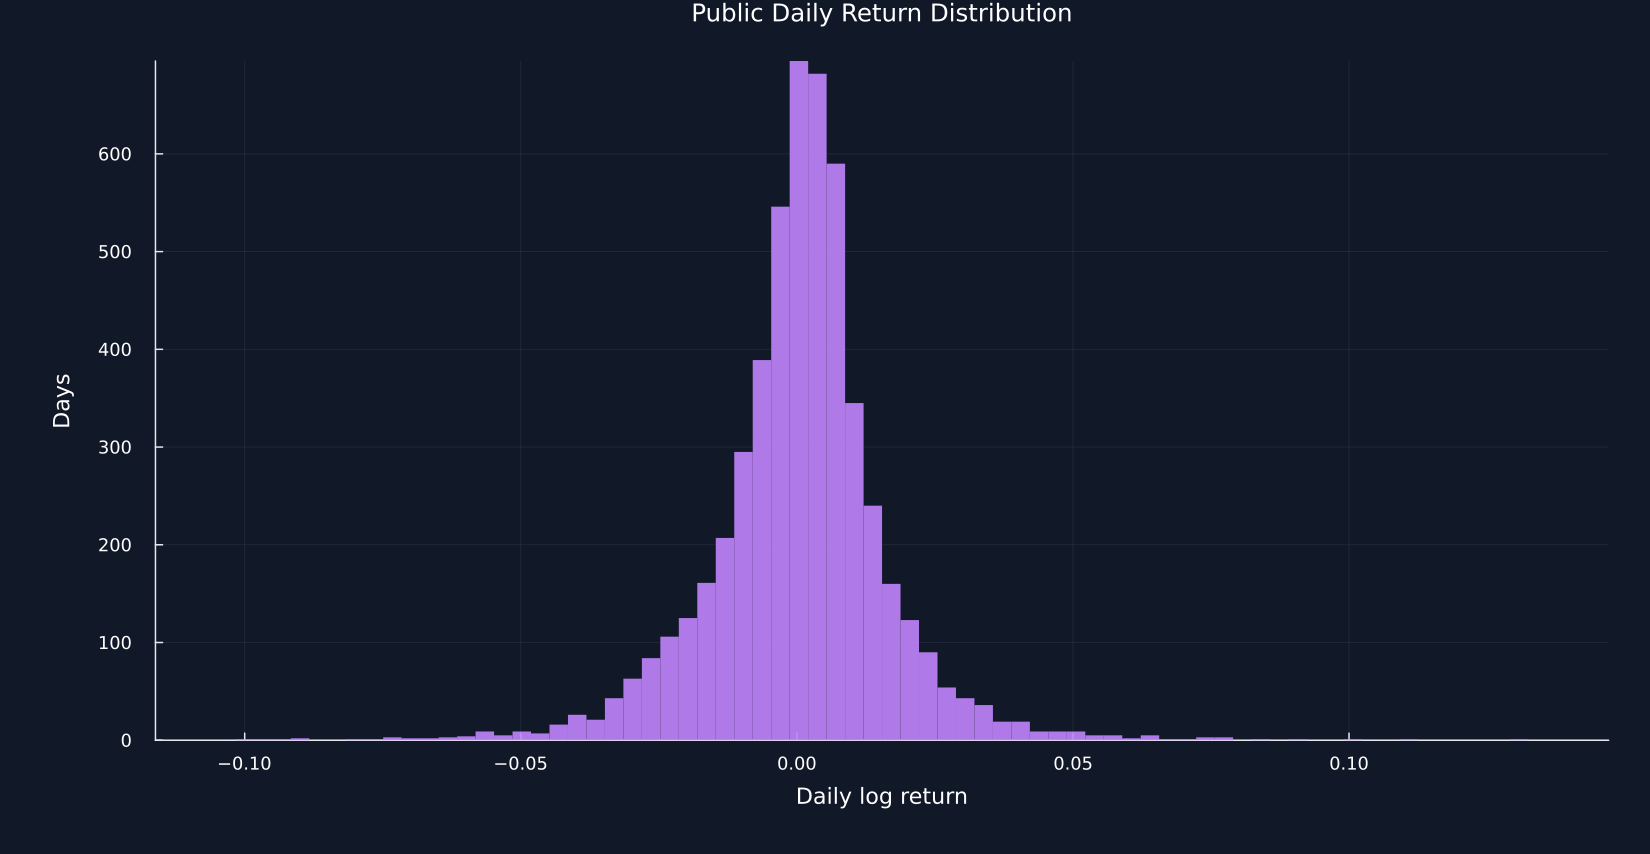

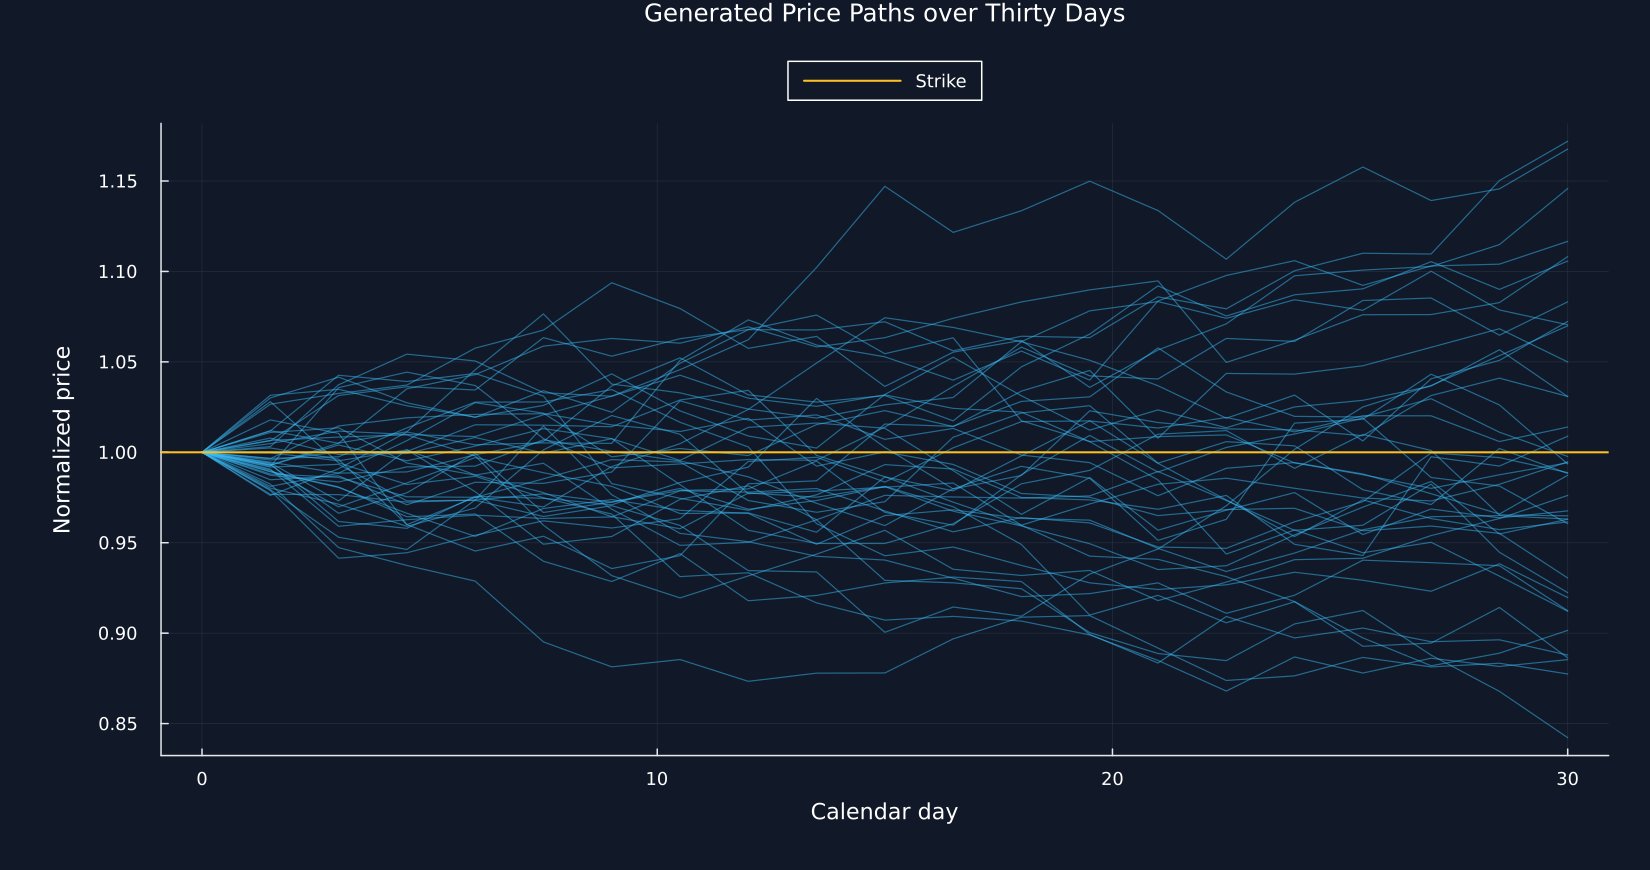

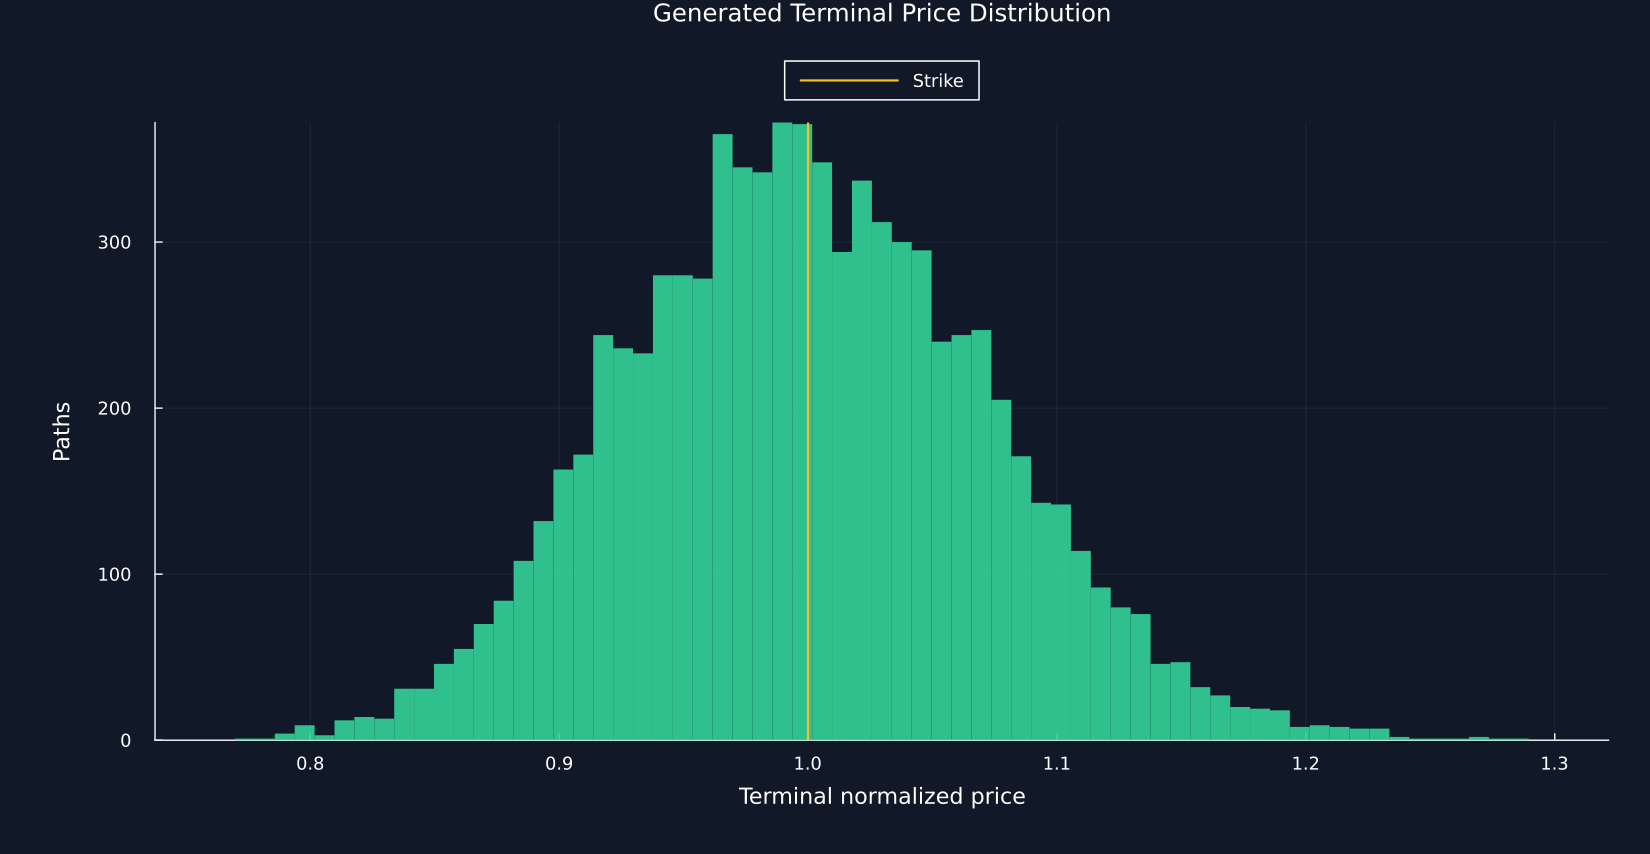

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("31_deep_hedging");
using CSV, TOML, Printf, Zygote
include(joinpath("..","support","BookHedging.jl"))
using .BookHedging
using RiskLabAI.Backtest: gbm_hedging_paths,black_scholes_call_delta,hedging_pnl,entropic_risk,DeepHedge,train_deep_hedge
default(left_margin=12Plots.mm,bottom_margin=10Plots.mm)
violet = "#C084FC"
random_root = joinpath("..","data","chapter31_random_inputs")
artifacts = joinpath(book_root(),"outputs","julia","artifacts","31_deep_hedging")
mkpath(artifacts)
data_file = dataset_path("fred_nasdaq")
full_public,public_design,public_observed,public_returns,sigma = public_volatility(data_file)
design = (spot=1.0,strike=1.0,maturity_days=30,maturity=30/365,volatility=sigma,drift=0.0,steps=20,cost_rate=.002,risk_aversion=3.0,hidden_size=16,learning_rate=.003,training_paths=2048,evaluation_paths=8192,iterations=200)
function table(frame,name,caption)
    shown = copy(frame)
    for column in names(shown)
        if eltype(shown[!,column])<:Bool
            shown[!,column] = ifelse.(shown[!,column],"Pass","Fail")
        end
    end
    save_table(shown,paths,name;caption,label="tab:chapter33-"*replace(name,"_"=>"-"))
    return nothing
end
function histogram_geometry(values,bins;density=false)
    lower,upper = extrema(values)
    if lower==upper
        lower,upper = lower-.5,upper+.5
    end
    edges = collect(range(lower,upper;length=bins+1))
    counts = zeros(Int,bins)
    for value in values
        index = clamp(searchsortedlast(edges,value),1,bins)
        counts[index] += 1
    end
    @assert sum(counts)==length(values)
    heights = density ? counts./length(values)./diff(edges) : Float64.(counts)
    return edges,heights
end
function draw_histogram!(figure,values,bins;color,label="",density=false,outline=false)
    edges,heights = histogram_geometry(values,bins;density)
    if outline
        x = vcat(edges[1],vec(permutedims(hcat(edges[1:end-1],edges[2:end]))),edges[end])
        y = vcat(0.0,repeat(heights;inner=2),0.0)
        plot!(figure,x,y;color,label,linewidth=1.7)
    else
        bar!(figure,(edges[1:end-1]+edges[2:end])/2,heights;bar_width=diff(edges),color,label,linealpha=0,alpha=.9)
    end
    return nothing
end
notation = DataFrame("Symbol"=>["S_k","K","T","N","phi_k","c","lambda","P"],"Description"=>["Underlying price at date k","Call strike","Time to maturity","Number of trading steps","Shares held during interval k","Proportional trading cost rate","Entropic risk aversion","Terminal hedge cash flow"],"Unit"=>["Normalized price","Normalized price","Years","Count","Shares","Fraction of traded value","Inverse cash flow unit","Cash flow unit"])
table(notation,"deep_hedging_notation","Notation for the one asset hedging study.")
assumptions = DataFrame("Feature"=>["Underlying assets","Liability","Path law","Interest and dividend rates","Trading cost","Final position","Risk measure","Final evaluation"],"Choice"=>["One","Short European call","Generated geometric Brownian motion","Zero","Proportional to traded value","Fully liquidated","Entropic risk","Independent generated paths"])
table(assumptions,"deep_hedging_assumptions","Assumptions of the bounded hedging study.")
quality = DataFrame("Check"=>["Rows in fixed file","Rows in design dates","Observed index levels","Observed log returns","Duplicate dates","Nonpositive observed levels"],"Value"=>[nrow(full_public),nrow(public_design),nrow(public_observed),length(public_returns),nrow(public_design)-length(unique(public_design.observation_date)),count(<=(0),public_observed.NASDAQCOM)],"Pass"=>[nrow(full_public)>8000,nrow(public_design)==5477,nrow(public_observed)==5287,length(public_returns)==5286,allunique(public_design.observation_date),all(>(0),public_observed.NASDAQCOM)])
@assert all(quality.Pass)
table(quality,"deep_hedging_public_data_quality","Quality checks for the fixed public design sample.")
provenance = DataFrame("Item"=>["Source","Series","Design start","Design end","Observed levels","Download during execution"],"Value"=>Any["Federal Reserve Economic Data","NASDAQCOM","January 4, 1994","December 31, 2014",nrow(public_observed),"None"])
table(provenance,"deep_hedging_public_data_provenance","Provenance of the public volatility scale.")
return_summary = DataFrame("Statistic"=>["Observations","Mean daily log return","Daily standard deviation","Annualized standard deviation","Minimum","First percentile","Median","Ninety-ninth percentile","Maximum"],"Value"=>[length(public_returns),mean(public_returns),std(public_returns),sigma,minimum(public_returns),quantile(public_returns,.01),median(public_returns),quantile(public_returns,.99),maximum(public_returns)])
table(return_summary,"deep_hedging_public_return_summary","Public daily return description for the fixed design period.")
design_table = DataFrame("Parameter"=>titlecase.(replace.(string.(collect(keys(design))),"_"=>" ")),"Value"=>collect(values(design)))
table(design_table,"deep_hedging_primary_design","Declared primary design for the generated hedging study.")
generated_contract = DataFrame("Item"=>["Generated object","Why generation is necessary","Public input","Generated market claim","Primary path seed","Download during execution"],"Value"=>["Option price paths and hedge cash flows","No approved public option panel contains the required synchronized paths and cost rule","Annualized volatility scale only","None",33001,"None"])
table(generated_contract,"deep_hedging_generated_data_contract","Boundary between the public scale and generated teaching paths.")
prices = hedge_paths(random_root,33001,design.evaluation_paths,design.steps,sigma)
twin = hedge_paths(random_root,33001,design.evaluation_paths,design.steps,sigma)
terminal_logs = log.(prices[:,end]./design.spot)
theoretical_mean = (design.drift-design.volatility^2/2)*design.maturity
theoretical_sd = design.volatility*sqrt(design.maturity)
mean_tolerance = 4theoretical_sd/sqrt(design.evaluation_paths)
sd_tolerance = 4theoretical_sd/sqrt(2(design.evaluation_paths-1))
moment_checks = DataFrame("Quantity"=>["Terminal log-return mean","Terminal log-return standard deviation","Smallest generated price"],"Observed"=>[mean(terminal_logs),std(terminal_logs),minimum(prices)],"Target"=>[theoretical_mean,theoretical_sd,0.0],"Tolerance"=>[mean_tolerance,sd_tolerance,0.0],"Pass"=>[abs(mean(terminal_logs)-theoretical_mean)<=mean_tolerance,abs(std(terminal_logs)-theoretical_sd)<=sd_tolerance,all(>(0),prices)])
@assert all(moment_checks.Pass)
table(moment_checks,"deep_hedging_gbm_moment_checks","Sample checks for the exact generated path law.")
reproducibility = DataFrame("Check"=>["Repeated seed gives identical paths","Path array rows","Path array columns","All prices finite"],"Value"=>Any[prices==twin,size(prices,1),size(prices,2),all(isfinite,prices)],"Pass"=>[prices==twin,size(prices,1)==design.evaluation_paths,size(prices,2)==design.steps+1,all(isfinite,prices)])
@assert all(reproducibility.Pass)
table(reproducibility,"deep_hedging_gbm_reproducibility","Reproducibility and shape checks for generated paths.")
public_path_data = DataFrame("Date"=>public_observed.observation_date,"Index level"=>public_observed.NASDAQCOM)
save_data(public_path_data,paths,"deep_hedging_public_index_path")
figure = plot(public_path_data.Date,public_path_data[!,"Index level"];color=palette.cyan,linewidth=1.2,title="Public NASDAQ Composite Design Sample",xlabel="Date",ylabel="Index level",legend=false,size=(1100,570))
save_figure(figure,paths,"deep_hedging_public_index_path")
save_data(DataFrame("Daily log return"=>public_returns),paths,"deep_hedging_public_return_distribution")
figure = plot(;title="Public Daily Return Distribution",xlabel="Daily log return",ylabel="Days",legend=false,size=(1100,570))
draw_histogram!(figure,public_returns,70;color=violet)
save_figure(figure,paths,"deep_hedging_public_return_distribution")
days = collect(range(0,design.maturity_days;length=design.steps+1))
fan = DataFrame("Day"=>days)
figure = plot(;title="Generated Price Paths over Thirty Days",xlabel="Calendar day",ylabel="Normalized price",size=(1100,580),legend=:outertop)
for index in 1:40
    fan[!,"Path $(index)"] = prices[index,:]
    plot!(figure,days,prices[index,:];color=palette.cyan,alpha=.5,linewidth=.8,label="")
end
hline!(figure,[design.strike];color=palette.amber,linewidth=1.4,label="Strike")
save_data(fan,paths,"deep_hedging_generated_paths")
save_figure(figure,paths,"deep_hedging_generated_paths")
terminal_data = DataFrame("Terminal price"=>prices[:,end])
save_data(terminal_data,paths,"deep_hedging_terminal_price_distribution")
figure = plot(;title="Generated Terminal Price Distribution",xlabel="Terminal normalized price",ylabel="Paths",legend=:outertop,size=(1100,570))
draw_histogram!(figure,prices[:,end],65;color=palette.green)
vline!(figure,[design.strike];color=palette.amber,label="Strike",linewidth=1.5)
save_figure(figure,paths,"deep_hedging_terminal_price_distribution")
open(joinpath(artifacts,"primary_design.toml"),"w") do stream
    TOML.print(stream,Dict(string(k)=>v for (k,v) in pairs(design)))
end
nothing


## Computing hedge cash flows after trading costs

For positions $\phi_0,\ldots,\phi_{N-1}$, set $\phi_{-1}=0$ before trading and $\phi_N=0$ after final liquidation. The terminal cash flow of a short call is

$$
P=p+\sum_{k=0}^{N-1}\phi_k(S_{k+1}-S_k)
-c\sum_{k=0}^{N}S_k\lvert\phi_k-\phi_{k-1}\rvert
-(S_N-K)^+.
$$

Here, $p$ is the option premium, the first sum is the hedge gain, $c$ is the proportional cost rate, and the final term is the call payoff owed at maturity. The cost sum includes the initial purchase, all later position changes, and final liquidation.

Row,Strategy,Mean hedge gain,Mean trading cost,Mean payoff,Mean terminal cash flow
,String,Float64,Float64,Float64,Float64
1,Zero hedge,0.0,0.0,0.0295106,-0.0295106
2,Constant half-share hedge,0.00023567,0.00200047,0.0295106,-0.0312754
3,Black-Scholes delta,0.000438356,0.00480324,0.0295106,-0.0338755


Row,Strategy,Maximum absolute difference,Pass
,String,Float64,String
1,Zero hedge,0.0,Pass
2,Constant half-share hedge,0.0,Pass
3,Black-Scholes delta,0.0,Pass


Row,Cost part,Mean cost
,String,Float64
1,Initial purchase,0.00102904
2,Later changes,0.00274006
3,Terminal liquidation,0.00103414
4,Total,0.00480324


Row,Date,Price,Holding before next move,Trade,Trading cost
,Int64,Float64,Float64?,Float64,Float64
1,0,1.0,0.51452,0.51452,0.00102904
2,1,0.98732,0.442614,-0.0719053,0.000141987
3,2,0.983595,0.418806,-0.023808,4.68349e-5
4,3,0.991931,0.465285,0.0464789,9.22078e-5
5,4,0.992362,0.466058,0.000772778,1.53375e-6
6,5,1.00695,0.556239,0.0901808,0.000181616
7,6,1.00054,0.51566,-0.0405784,8.12004e-5
8,7,0.995218,0.479138,-0.0365224,7.26954e-5
9,8,0.98644,0.415313,-0.0638246,0.000125918


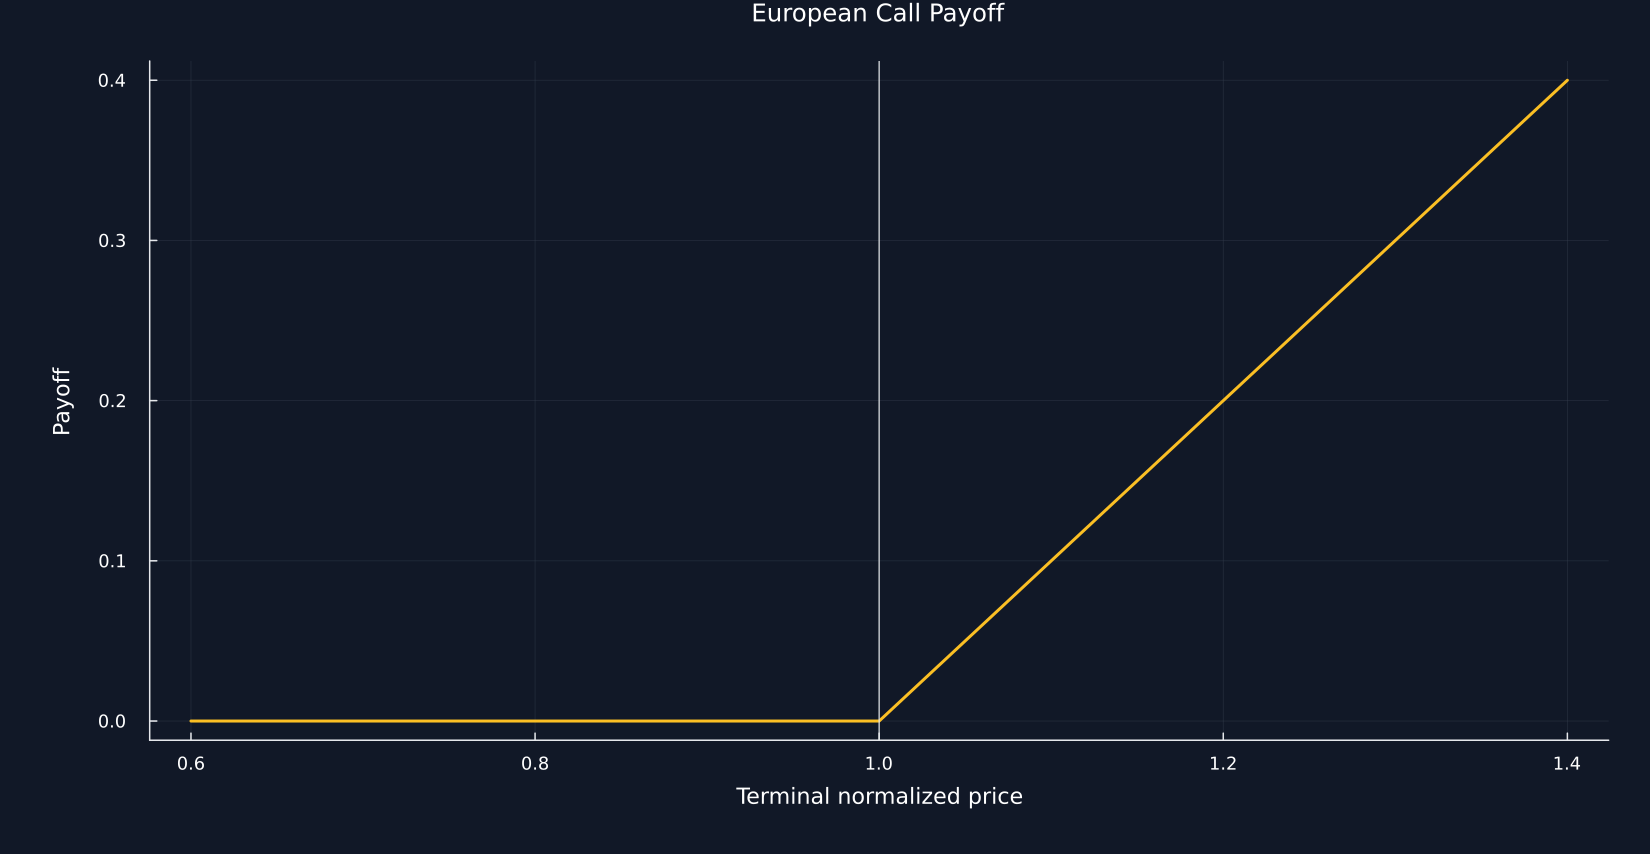

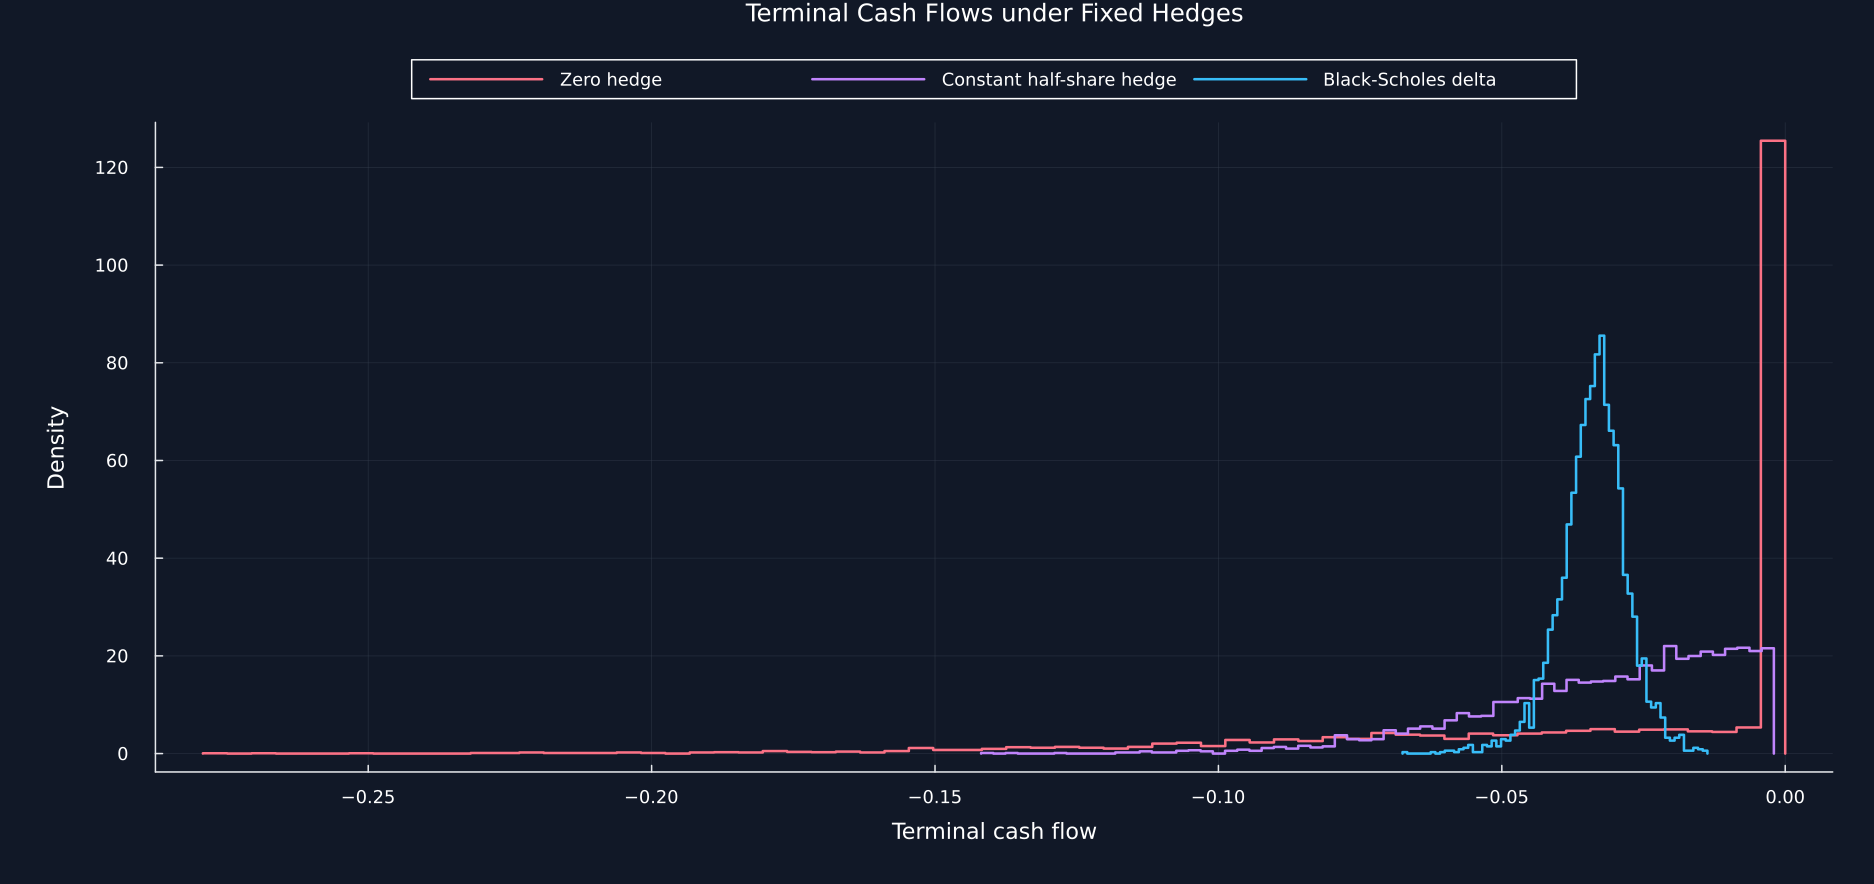

In [2]:
evaluation_prices = prices[1:4096,:]
delta_positions = black_scholes_call_delta(evaluation_prices;strike=design.strike,maturity=design.maturity,volatility=design.volatility)
zero_positions = zeros(size(delta_positions))
half_positions = fill(.5,size(delta_positions))
cashflow_rows,recalculation_rows = NamedTuple[],NamedTuple[]
for (name,positions) in [("Zero hedge",zero_positions),("Constant half-share hedge",half_positions),("Black-Scholes delta",delta_positions)]
    components = cashflow_components(evaluation_prices,positions,design.strike,design.cost_rate)
    released = hedging_pnl(evaluation_prices,positions;strike=design.strike,cost_rate=design.cost_rate)
    push!(cashflow_rows,(Strategy=name,gains=mean(components.gains),costs=mean(components.costs),payoff=mean(components.payoff),pnl=mean(components.pnl)))
    push!(recalculation_rows,(Strategy=name,difference=maximum(abs.(released-components.pnl)),Pass=all(isapprox.(released,components.pnl;atol=1e-13,rtol=0))))
end
cashflow_summary = rename!(DataFrame(cashflow_rows),["Strategy","Mean hedge gain","Mean trading cost","Mean payoff","Mean terminal cash flow"])
table(cashflow_summary,"deep_hedging_cashflow_summary","Cash flow components under three fixed hedges.")
recalculation = rename!(DataFrame(recalculation_rows),["Strategy","Maximum absolute difference","Pass"])
@assert all(recalculation.Pass)
table(recalculation,"deep_hedging_cashflow_recalculation","Independent cash flow recomputation against the released function.")
delta_components = cashflow_components(evaluation_prices,delta_positions,design.strike,design.cost_rate)
delta_trades = delta_components.trades
cost_breakdown = DataFrame("Cost part"=>["Initial purchase","Later changes","Terminal liquidation","Total"],"Mean cost"=>[mean(design.cost_rate.*evaluation_prices[:,1].*abs.(delta_trades[:,1])),mean(vec(sum(design.cost_rate.*evaluation_prices[:,2:end-1].*abs.(delta_trades[:,2:end-1]);dims=2))),mean(design.cost_rate.*evaluation_prices[:,end].*abs.(delta_trades[:,end])),mean(delta_components.costs)])
@assert isapprox(sum(cost_breakdown[1:3,"Mean cost"]),cost_breakdown[4,"Mean cost"];atol=1e-14)
table(cost_breakdown,"deep_hedging_cost_breakdown","Mean Black-Scholes delta cost from initial purchase through liquidation.")
path_table = DataFrame("Date"=>0:design.steps,"Price"=>evaluation_prices[1,:],"Holding before next move"=>vcat(delta_positions[1,:],missing),"Trade"=>delta_trades[1,:],"Trading cost"=>design.cost_rate.*evaluation_prices[1,:].*abs.(delta_trades[1,:]))
table(path_table,"deep_hedging_single_path_cashflows","One generated path with delta holdings, trades, and costs.")
payoff_prices = collect(range(.6,1.4;length=241))
payoff_data = DataFrame("Terminal price"=>payoff_prices,"Call payoff"=>max.(payoff_prices.-design.strike,0.0))
save_data(payoff_data,paths,"deep_hedging_call_payoff")
figure = plot(payoff_prices,payoff_data[!,"Call payoff"];color=palette.amber,title="European Call Payoff",xlabel="Terminal normalized price",ylabel="Payoff",legend=false,size=(1100,570))
vline!(figure,[design.strike];color=palette.text,linewidth=1,alpha=.8)
save_figure(figure,paths,"deep_hedging_call_payoff")
cashflow_data = DataFrame("Zero hedge"=>cashflow_components(evaluation_prices,zero_positions,design.strike,design.cost_rate).pnl,"Constant half-share hedge"=>cashflow_components(evaluation_prices,half_positions,design.strike,design.cost_rate).pnl,"Black-Scholes delta"=>delta_components.pnl)
save_data(cashflow_data,paths,"deep_hedging_fixed_cashflow_distributions")
figure = plot(;title="Terminal Cash Flows under Fixed Hedges",xlabel="Terminal cash flow",ylabel="Density",legend=:outertop,legend_columns=3,size=(1250,590))
for (name,color) in [("Zero hedge",palette.rose),("Constant half-share hedge",violet),("Black-Scholes delta",palette.cyan)]
    draw_histogram!(figure,cashflow_data[!,name],65;color,label=name,density=true,outline=true)
end
save_figure(figure,paths,"deep_hedging_fixed_cashflow_distributions")
nothing


### Entropic Risk

The chapter evaluates a terminal cash flow $P$ with

$$
\rho_{\lambda}(P)=\frac{1}{\lambda}\log E\!\left[e^{-\lambda P}\right],
\qquad \lambda>0.
$$

The parameter $\lambda$ controls how strongly low cash flows influence the result. A larger value gives more weight to adverse outcomes. This is one declared risk preference, not a universal measure of investment quality.

Row,Risk aversion,Released value,Independent value,Absolute difference,Translation residual
,Float64,Float64,Float64,Float64,Float64
1,0.1,0.0338773,0.0338773,1.52101e-14,0.0
2,0.5,0.0338843,0.0338843,3.11556e-15,0.0
3,1.0,0.033893,0.033893,6.52256e-16,0.0
4,3.0,0.0339281,0.0339281,4.996e-16,0.0
5,10.0,0.034052,0.034052,3.46945e-17,0.0


Row,Case,Rejected,Result
,String,String,String
1,Zero spot,Pass,Invalid input
2,Zero maturity,Pass,Invalid input
3,Negative volatility,Pass,Invalid input
4,Zero steps,Pass,Invalid input
5,Zero path count,Pass,Invalid input
6,Zero risk aversion,Pass,Invalid input
7,Zero delta volatility,Pass,Invalid input


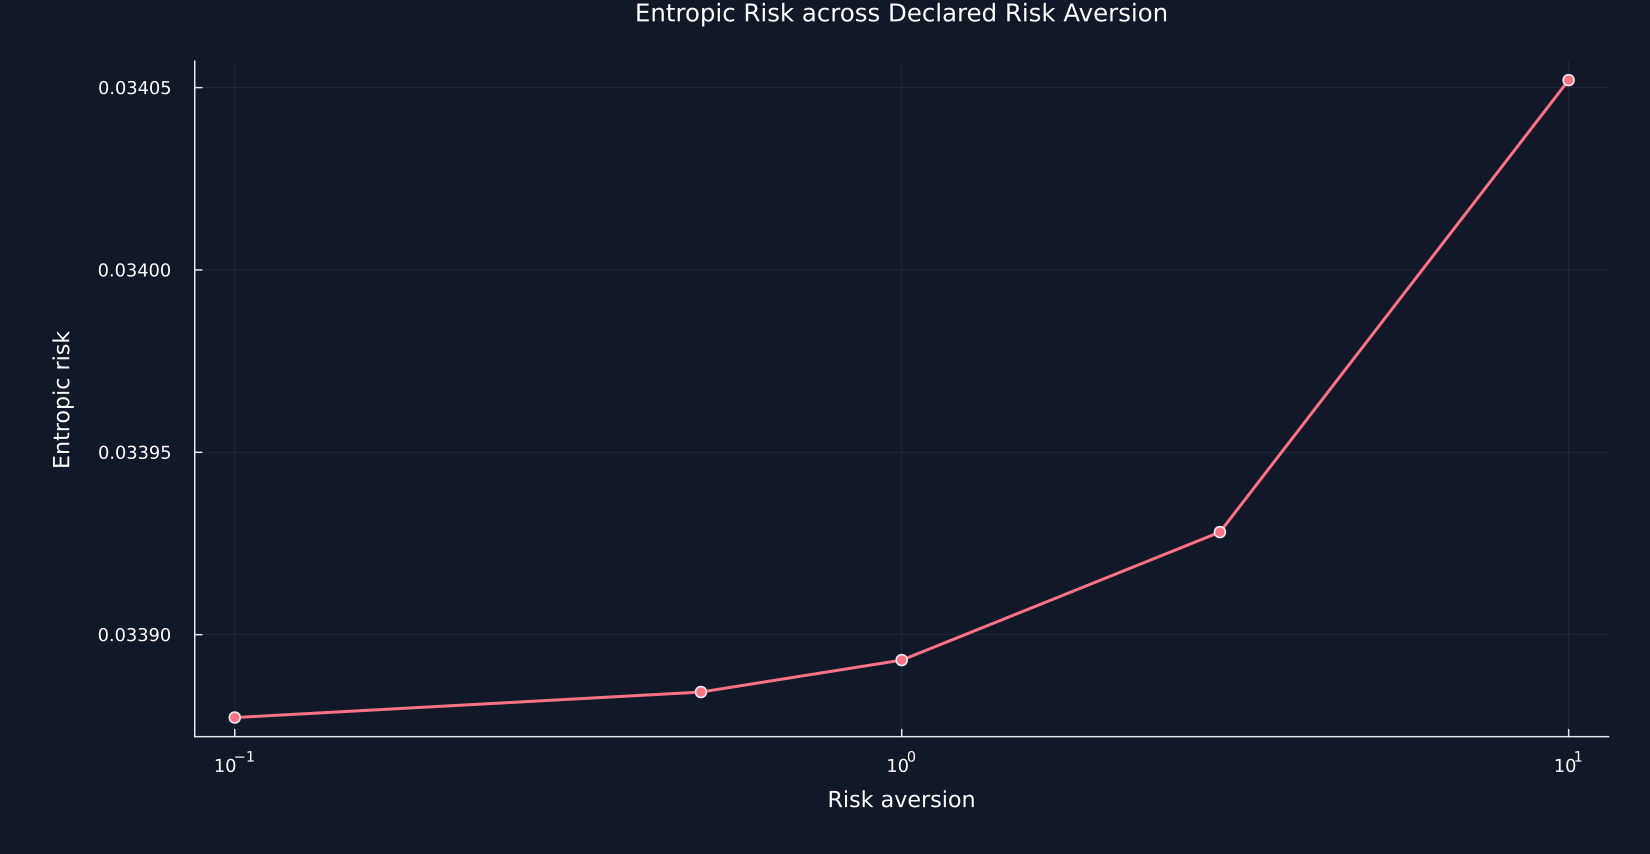

In [3]:
risk_rows = NamedTuple[]
delta_pnl = delta_components.pnl
for value in [.1,.5,1.,3.,10.]
    anchor = minimum(delta_pnl)
    independent = -anchor+log(mean(exp.(-value.*(delta_pnl.-anchor))))/value
    released = entropic_risk(delta_pnl,value)
    push!(risk_rows,(aversion=value,released=released,independent=independent,difference=abs(released-independent),translation=abs(entropic_risk(delta_pnl.+50000,value)-(released-50000))))
end
entropic_checks = rename!(DataFrame(risk_rows),["Risk aversion","Released value","Independent value","Absolute difference","Translation residual"])
@assert maximum(entropic_checks[!,"Absolute difference"])<1e-12
@assert maximum(entropic_checks[!,"Translation residual"])<1e-9
table(entropic_checks,"deep_hedging_entropic_risk_checks","Stable and independently recomputed entropic-risk values.")
invalid_cases = [
    "Zero spot"=>(() -> gbm_hedging_paths(;spot=0,maturity=1,volatility=.2,drift=0,steps=2,paths=2,seed=1)),
    "Zero maturity"=>(() -> gbm_hedging_paths(;spot=1,maturity=0,volatility=.2,drift=0,steps=2,paths=2,seed=1)),
    "Negative volatility"=>(() -> gbm_hedging_paths(;spot=1,maturity=1,volatility=-.2,drift=0,steps=2,paths=2,seed=1)),
    "Zero steps"=>(() -> gbm_hedging_paths(;spot=1,maturity=1,volatility=.2,drift=0,steps=0,paths=2,seed=1)),
    "Zero path count"=>(() -> gbm_hedging_paths(;spot=1,maturity=1,volatility=.2,drift=0,steps=2,paths=0,seed=1)),
    "Zero risk aversion"=>(() -> entropic_risk(ones(2),0)),
    "Zero delta volatility"=>(() -> black_scholes_call_delta(ones(2,3);strike=1,maturity=1,volatility=0))]
invalid_rows = NamedTuple[]
for (name,action) in invalid_cases
    rejected = try
        action()
        false
    catch error
        error isa ArgumentError
    end
    push!(invalid_rows,(Case=name,Rejected=rejected,Result=rejected ? "Invalid input" : "Accepted"))
end
invalid_checks = DataFrame(invalid_rows)
@assert all(invalid_checks.Rejected)
table(invalid_checks,"deep_hedging_invalid_input_checks","Invalid inputs rejected by the released calculations.")
risk_curve = rename(entropic_checks[:,["Risk aversion","Released value"]],"Released value"=>"Entropic risk")
save_data(risk_curve,paths,"deep_hedging_entropic_risk_curve")
figure = plot(risk_curve[!,"Risk aversion"],risk_curve[!,"Entropic risk"];color=palette.rose,marker=:circle,xscale=:log10,title="Entropic Risk across Declared Risk Aversion",xlabel="Risk aversion",ylabel="Entropic risk",legend=false,size=(1100,570))
save_figure(figure,paths,"deep_hedging_entropic_risk_curve")
nothing
